# PDAN8412 POE Part 2: Predicting Kindle Best Sellers with Logistic Regression Built From Scratch

A book press wants to know, before investing in a title, whether a book is likely to become an Amazon best seller. In this notebook we use the Amazon Kindle Books Dataset 2023 (about 130 thousand books, published on Kaggle by asaniczka) and build a Logistic Regression model completely from scratch in NumPy to predict the `isBestSeller` column.

The workflow follows the same approach as our class notebook: load the data into an array, normalise the features, define a sigmoid function, define a cost function, and use gradient descent to update the weights and bias. scikit learn is only used for splitting, scaling, metrics and a final comparison model.

## 1. Imports and Loading the Data

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
%matplotlib inline

warnings.filterwarnings('ignore')

# Same seed everywhere so results can be reproduced
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Folder for all report charts
os.makedirs('figures', exist_ok=True)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')


def save_fig(name):
    # Save the current chart into the figures folder
    plt.tight_layout()
    plt.savefig(os.path.join('figures', name), dpi=150, bbox_inches='tight')

This cell loads every library the notebook needs. NumPy and pandas handle the data, matplotlib and seaborn draw the charts, and statsmodels gives us p values for feature selection. From scikit learn we only import tools for splitting, scaling, scoring and the final comparison model, because the logistic regression itself will be written by hand. We set `RANDOM_STATE = 42` and seed NumPy so that every run gives the same results, create a `figures` folder, and write a small `save_fig` helper so every chart is saved for the report. There is no output because this cell only prepares the environment.

In [2]:
df = pd.read_csv('kindle_data-v2.csv')
print('Shape:', df.shape)

Shape: (133102, 16)


Here we read the Kindle CSV file into a pandas DataFrame called `df`. The output shows the dataset has 133,102 rows and 16 columns, so every row is one Kindle book and every column is one piece of information about it.

In [3]:
df.head()

,asin,title,author,soldBy,imgUrl,productURL,stars,reviews,price,isKindleUnlimited,category_id,isBestSeller,isEditorsPick,isGoodReadsChoice,publishedDate,category_name
0,B00TZE87S4,Adult Children of Emotionally Immature Parents...,Lindsay C. Gibson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/713KZTsaYp...,https://www.amazon.com/dp/B00TZE87S4,4.8,0,9.99,False,6,True,False,False,2015-06-01,Parenting & Relationships
1,B08WCKY8MB,"From Strength to Strength: Finding Success, Ha...",Arthur C. Brooks,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/A1LZcJFs9E...,https://www.amazon.com/dp/B08WCKY8MB,4.4,0,16.99,False,6,False,False,False,2022-02-15,Parenting & Relationships
2,B09KPS84CJ,Good Inside: A Guide to Becoming the Parent Yo...,Becky Kennedy,HarperCollins Publishers,https://m.media-amazon.com/images/I/71RIWM0sv6...,https://www.amazon.com/dp/B09KPS84CJ,4.8,0,16.99,False,6,False,True,False,2022-09-13,Parenting & Relationships
3,B07S7QPG6J,Everything I Know About Love: A Memoir,Dolly Alderton,HarperCollins Publishers,https://m.media-amazon.com/images/I/71QdQpTiKZ...,https://www.amazon.com/dp/B07S7QPG6J,4.2,0,9.95,True,6,False,True,False,2020-02-25,Parenting & Relationships
4,B00N6PEQV0,The Seven Principles for Making Marriage Work:...,John Gottman,Random House LLC,https://m.media-amazon.com/images/I/813o4WOs+w...,https://www.amazon.com/dp/B00N6PEQV0,4.7,0,13.99,False,6,False,False,False,2015-05-05,Parenting & Relationships


`head()` shows the first five books so we can see what the data looks like. Each book has an id (`asin`), a title, an author, the seller, two web links, the star rating, the number of reviews, the price, a Kindle Unlimited flag, a category, three badge columns (`isBestSeller`, `isEditorsPick`, `isGoodReadsChoice`) and a published date. Already we can see something odd: the first book has 4.8 stars but 0 reviews, which we will investigate in the data quality section.

In [4]:
df.dtypes

asin                  object
title                 object
author                object
soldBy                object
imgUrl                object
productURL            object
stars                float64
reviews                int64
price                float64
isKindleUnlimited       bool
category_id            int64
isBestSeller            bool
isEditorsPick           bool
isGoodReadsChoice       bool
publishedDate         object
category_name         object
dtype: object

This shows the data type of every column. Stars and price are decimals, reviews and category_id are whole numbers, the four badge and Kindle Unlimited columns are True or False values, and the rest are text (object). The `publishedDate` column is stored as text, so it must be converted into a real date before we can calculate a book's age.

In [5]:
df.describe()

,stars,reviews,price,category_id
count,133102.000000,133102.000000,133102.000000,133102.000000
mean,4.404090,887.375779,15.134127,16.287111
std,0.745646,5104.878777,22.254986,8.416924
min,0.000000,0.000000,0.000000,1.000000
25%,4.400000,0.000000,4.990000,9.000000
50%,4.500000,4.000000,9.990000,16.000000
75%,4.700000,365.000000,14.990000,23.000000
max,5.000000,618227.000000,682.000000,31.000000


`describe()` gives summary statistics for the numeric columns. The average rating is 4.40 stars, but the minimum is 0, which is suspicious for a 1 to 5 star scale. Reviews are extremely skewed: the median is only 4 but the maximum is 618,227 and the mean (887) is much bigger than the median. Price ranges from 0 to 682 dollars with a median of 9.99 dollars, so price also has a long tail of very expensive books.

## 2. Data Quality

### 2.1 Missing values

In [6]:
missing = pd.DataFrame({'missing_count': df.isnull().sum(),
                        'missing_percent': (df.isnull().mean() * 100).round(2)})
missing.sort_values('missing_count', ascending=False)

,missing_count,missing_percent
publishedDate,49016,36.83
soldBy,9233,6.94
author,425,0.32
asin,0,0.00
title,0,0.00
imgUrl,0,0.00
productURL,0,0.00
stars,0,0.00
reviews,0,0.00
price,0,0.00


This table counts the missing values in each column. `publishedDate` is missing for 49,016 books (36.83 percent), `soldBy` is missing for 9,233 books (6.94 percent) and `author` is missing for 425 books (0.32 percent). Every other column is complete, including the target. Dropping all rows without a date would throw away more than a third of the data, so instead we will keep those rows and add a flag that tells the model the date was missing.

### 2.2 Duplicates

In [7]:
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicated asin (book id):', df['asin'].duplicated().sum())
print('Rows sharing the same title and author:', df.duplicated(['title', 'author']).sum())

# Look at an example of the same title and author appearing twice
dup = df[df.duplicated(['title', 'author'], keep=False)].sort_values('title')
dup[['asin', 'title', 'author', 'price', 'category_name', 'isBestSeller']].head(6)

Fully duplicated rows: 0
Duplicated asin (book id): 0
Rows sharing the same title and author: 847


,asin,title,author,price,category_name,isBestSeller
93902,B00LD1OBMI,10-Day Green Smoothie Cleanse: Lose Up to 15 P...,JJ Smith,13.99,Nonfiction,False
92900,B00QASO8GI,10-Day Green Smoothie Cleanse: Lose Up to 15 P...,JJ Smith,0.00,"Cookbooks, Food & Wine",False
52673,B07RQ3RXDH,100 Days of Sunlight,Abbie Emmons,7.99,Teen & Young Adult,False
129078,1733973311,100 Days of Sunlight,Abbie Emmons,12.69,Children's eBooks,False
127449,B0009S2F0G,1776,David McCullough,0.00,Children's eBooks,False
32940,B000FCK5YE,1776,David McCullough,13.99,Biographies & Memoirs,False


Here we look for duplicates in three ways. There are no fully duplicated rows and no repeated `asin`, so every row is a unique Amazon product. There are 847 rows that share a title and author with another row, but the example table shows these are different listings of the same book, for example a free edition and a paid edition in different categories with different prices. Because each one is a separate product with its own price and badge, we keep them.

### 2.3 Data types

In [8]:
# Convert the date text into a real date
df['publishedDate'] = pd.to_datetime(df['publishedDate'], errors='coerce')

# Convert True/False columns to 1/0
bool_cols = ['isKindleUnlimited', 'isBestSeller', 'isEditorsPick', 'isGoodReadsChoice']
df[bool_cols] = df[bool_cols].astype(int)

print(df[['publishedDate'] + bool_cols].dtypes)
print('Earliest date:', df['publishedDate'].min(), ' Latest date:', df['publishedDate'].max())

publishedDate        datetime64[ns]
isKindleUnlimited             int64
isBestSeller                  int64
isEditorsPick                 int64
isGoodReadsChoice             int64
dtype: object
Earliest date: 1806-01-01 00:00:00  Latest date: 2024-01-16 00:00:00


This cell fixes the data types. The published date is converted from text into a proper datetime, and the four True or False columns are converted into 1 and 0 so the model can use them as numbers. The output confirms the new types and shows that the dates run from 1806 to January 2024. The very old dates are classic books that were republished on Kindle, so they are real values and not errors.

### 2.4 Invalid values

In [9]:
print('Books with price 0:', (df['price'] == 0).sum())
print('Books with stars 0 and 0 reviews:', ((df['stars'] == 0) & (df['reviews'] == 0)).sum())
print('Books with stars 0 but some reviews:', ((df['stars'] == 0) & (df['reviews'] > 0)).sum())
print('Books with stars above 0 but 0 reviews:', ((df['stars'] > 0) & (df['reviews'] == 0)).sum())
print('Books with stars outside 0 to 5:', ((df['stars'] < 0) | (df['stars'] > 5)).sum())
print('Books with a negative price:', (df['price'] < 0).sum())
print('Books published before 1900:', (df['publishedDate'] < '1900-01-01').sum())

# Best seller rate inside each suspicious group
print()
print('Best seller rate overall:      ', round(df['isBestSeller'].mean() * 100, 2), '%')
print('Best seller rate when price 0: ', round(df.loc[df['price'] == 0, 'isBestSeller'].mean() * 100, 2), '%')
print('Best seller rate when stars 0: ', round(df.loc[df['stars'] == 0, 'isBestSeller'].mean() * 100, 2), '%')

Books with price 0: 4066
Books with stars 0 and 0 reviews: 3182
Books with stars 0 but some reviews: 0
Books with stars above 0 but 0 reviews: 61488
Books with stars outside 0 to 5: 0
Books with a negative price: 0
Books published before 1900: 1

Best seller rate overall:       1.68 %
Best seller rate when price 0:  2.26 %
Best seller rate when stars 0:  0.16 %


This cell checks for values that do not make sense. 4,066 books have a price of 0, but these are genuine free books, and they actually have a slightly higher best seller rate (2.26 percent) than the overall rate (1.68 percent), so they are kept and given their own flag. 3,182 books have 0 stars and 0 reviews; a rating of 0 is impossible on Amazon, so these books are simply not rated yet. There are no books with 0 stars but some reviews, no ratings above 5 and no negative prices. We also see that 61,488 books have a real star rating but 0 reviews, which is the strange pattern we spotted in the head of the data.

In [10]:
# Share of books with 0 reviews in each category
zero_rev = (df.assign(zero_reviews=(df['reviews'] == 0))
              .groupby('category_name')['zero_reviews'].mean() * 100).sort_values()
print('Categories where every book has 0 reviews:', (zero_rev >= 99.5).sum())
print('Categories where almost no book has 0 reviews:', (zero_rev <= 5).sum())
zero_rev.round(1).to_frame('percent_with_0_reviews').T

Categories where every book has 0 reviews: 12
Categories where almost no book has 0 reviews: 15


category_name,Comics,Literature & Fiction,Science Fiction & Fantasy,Teen & Young Adult,LGBTQ+ eBooks,Religion & Spirituality,Biographies & Memoirs,History,Nonfiction,Politics & Social Sciences,Arts & Photo graphy,Education & Teaching,Travel,Self-Help,Foreign Language,Computers & Technology,"Cookbooks, Food & Wine",Parenting & Relationships,"Crafts, Hobbies & Home","Mystery, Thriller & Suspense",Sports & Outdoors,Business & Money,Science & Math,Romance,Humor & Entertainment,Reference,"Health, Fitness & Dieting",Medical,Engineering & Transportation,Children's eBooks,Law
percent_with_0_reviews,0.0,0.0,0.1,0.1,0.5,0.7,0.7,1.3,1.4,1.9,2.5,3.5,3.6,4.1,4.4,5.4,78.4,87.6,92.5,99.9,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


To understand the 0 reviews problem we calculated the percentage of books with 0 reviews inside each category. The result is very clear: in 12 categories (for example Romance, Law, Medical and Business & Money) basically every single book has 0 reviews, while in 15 other categories almost no book has 0 reviews. This means the review count was simply not collected for some categories when the data was scraped. So "0 reviews" does not really mean a book has no reviews; it mostly tells us which category the book is in. We therefore do not create a separate "has no reviews" feature, and we treat the review column with caution.

### 2.5 Outliers

stars    outliers:   7252   max: 5.0
reviews  outliers:  20876   max: 618227
price    outliers:  13491   max: 682.0


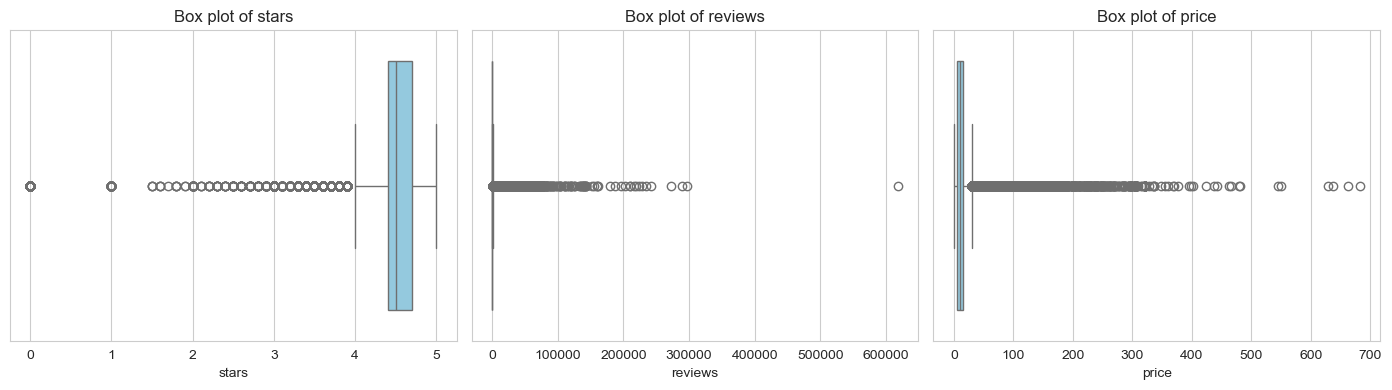

In [11]:
def iqr_outliers(series):
    # Count values outside 1.5 times the IQR
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

for col in ['stars', 'reviews', 'price']:
    print(f'{col:8s} outliers: {iqr_outliers(df[col]):6d}   max: {df[col].max()}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['stars', 'reviews', 'price']):
    sns.boxplot(x=df[col], ax=ax, color='skyblue')
    ax.set_title(f'Box plot of {col}')
save_fig('01_outliers_boxplots.png')
plt.show()

This cell counts outliers using the IQR rule (values more than 1.5 times the interquartile range beyond the first or third quartile) and draws box plots. Stars has 7,252 outliers, which are the low ratings and the 0 values; reviews has 20,876 outliers and price has 13,491. The box plots show that reviews and price are squashed against the left with a few huge values stretching to the right. These large values are real books (very popular titles and expensive textbooks), so removing them would delete genuine information. Instead we will use a log transform later, which pulls the long tail in while keeping every book.

### 2.6 Cleaning decisions

In [12]:
df_clean = df.copy()

# Stars 0 with 0 reviews means "not rated yet", not a real rating of 0
df_clean['is_unrated'] = ((df_clean['stars'] == 0) & (df_clean['reviews'] == 0)).astype(int)
df_clean.loc[df_clean['is_unrated'] == 1, 'stars'] = np.nan
df_clean['stars'] = df_clean['stars'].fillna(df_clean['stars'].median())

# Price 0 is a real free book, so keep it and flag it
df_clean['is_free'] = (df_clean['price'] == 0).astype(int)

# Missing seller becomes its own group
df_clean['soldBy'] = df_clean['soldBy'].fillna('Unknown')

# Missing published date gets a flag (it is filled later from training data only)
df_clean['date_missing'] = df_clean['publishedDate'].isnull().astype(int)

print('Shape after cleaning:', df_clean.shape)
df_clean[['stars', 'is_unrated', 'is_free', 'date_missing']].describe()

Shape after cleaning: (133102, 19)


,stars,is_unrated,is_free,date_missing
count,133102.000000,133102.000000,133102.000000,133102.000000
mean,4.511669,0.023906,0.030548,0.368259
std,0.284500,0.152758,0.172090,0.482334
min,1.000000,0.000000,0.000000,0.000000
25%,4.400000,0.000000,0.000000,0.000000
50%,4.500000,0.000000,0.000000,0.000000
75%,4.700000,0.000000,0.000000,1.000000
max,5.000000,1.000000,1.000000,1.000000


This cell applies the cleaning decisions. Books with 0 stars and 0 reviews are flagged as `is_unrated` and their star value is replaced with the median rating so the 0 does not drag the stars column down. Free books are kept and flagged with `is_free`. A missing seller becomes its own group called "Unknown", and books without a published date get a `date_missing` flag. The shape is still 133,102 rows, so no books were lost, and the summary shows the minimum star rating is now 1 instead of 0. About 2.4 percent of books are unrated, 3.1 percent are free and 36.8 percent are missing a date.

## 3. Exploratory Data Analysis

               count  percent
isBestSeller                 
0             130866    98.32
1               2236     1.68


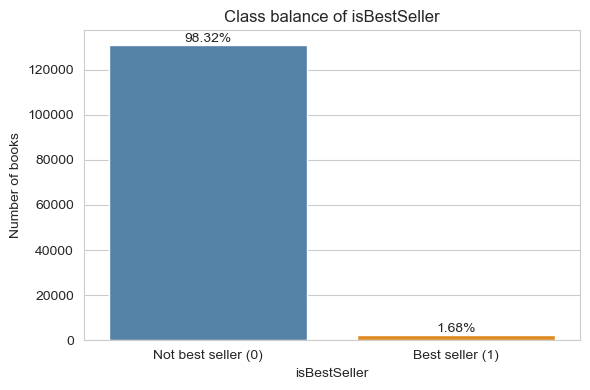

In [13]:
counts = df_clean['isBestSeller'].value_counts().sort_index()
percent = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({'count': counts, 'percent': percent}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='isBestSeller', data=df_clean, palette=['steelblue', 'darkorange'])
for p, pct in zip(ax.patches, percent):
    ax.annotate(f'{pct}%', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.xticks([0, 1], ['Not best seller (0)', 'Best seller (1)'])
plt.title('Class balance of isBestSeller')
plt.ylabel('Number of books')
save_fig('02_class_balance.png')
plt.show()

This chart shows the class balance of the target. Only 2,236 books (1.68 percent) are best sellers, while 130,866 books (98.32 percent) are not. The data is therefore very imbalanced, which is the most important fact for the whole project: a model that always says "not a best seller" would already be 98.32 percent accurate while being completely useless to the book press.

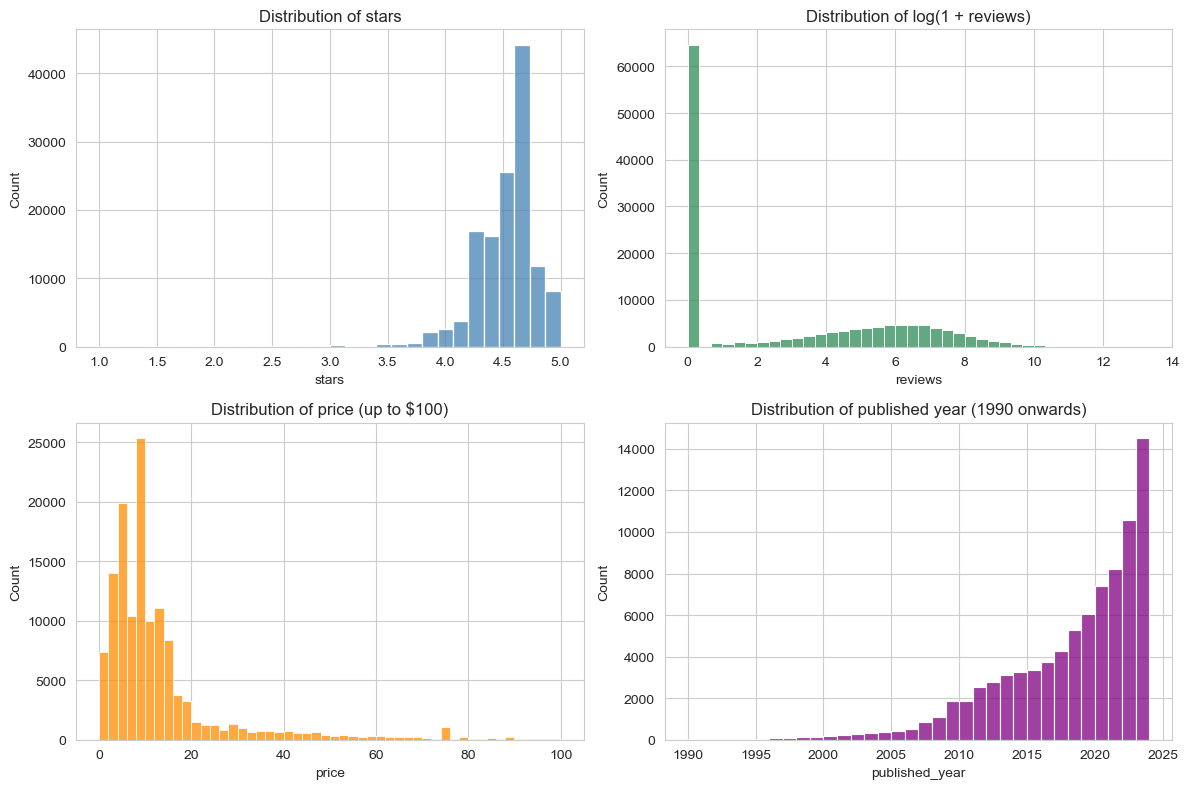

In [14]:
df_clean['published_year'] = df_clean['publishedDate'].dt.year

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df_clean['stars'], bins=30, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Distribution of stars')
sns.histplot(np.log1p(df_clean['reviews']), bins=40, ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('Distribution of log(1 + reviews)')
sns.histplot(df_clean.loc[df_clean['price'] <= 100, 'price'], bins=50, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Distribution of price (up to $100)')
sns.histplot(df_clean.loc[df_clean['published_year'] >= 1990, 'published_year'], bins=34, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribution of published year (1990 onwards)')
save_fig('03_numeric_distributions.png')
plt.show()

These four histograms show the shape of the main numeric features. Stars are bunched between about 4.2 and 4.8, so most books are rated highly and the rating does not separate books very much. The log of reviews has a huge spike at 0 (the categories where reviews were not collected) and then a spread of values for the rest. Price is right skewed, with most books under 20 dollars. The published year chart shows the number of books grows strongly after 2010 and peaks in 2023, so the dataset is dominated by recent books.

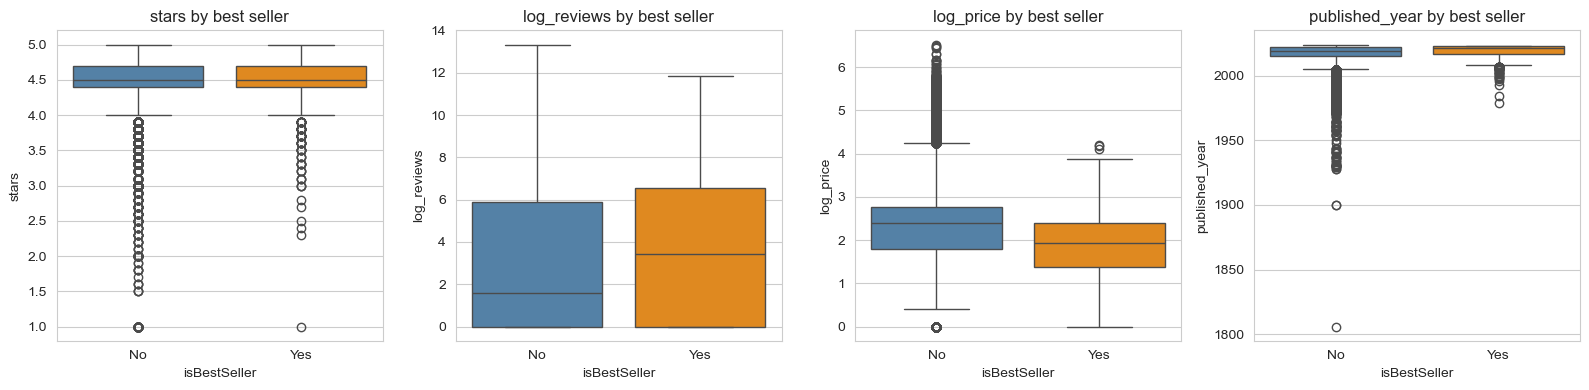

,stars,reviews,price,published_year
isBestSeller,,,,
0,4.5,4.0,9.99,2019.0
1,4.5,30.0,5.99,2021.0


In [15]:
plot_df = df_clean.copy()
plot_df['log_reviews'] = np.log1p(plot_df['reviews'])
plot_df['log_price'] = np.log1p(plot_df['price'])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['stars', 'log_reviews', 'log_price', 'published_year']):
    sns.boxplot(x='isBestSeller', y=col, data=plot_df, ax=ax, palette=['steelblue', 'darkorange'])
    ax.set_title(f'{col} by best seller')
    ax.set_xticklabels(['No', 'Yes'])
save_fig('04_boxplots_by_bestseller.png')
plt.show()

plot_df.groupby('isBestSeller')[['stars', 'reviews', 'price', 'published_year']].median()

These box plots compare best sellers (Yes) with other books (No) for each feature. The star ratings look almost the same for both groups (median 4.5 for both). Best sellers have a higher median number of reviews (30 compared with 4) and a lower median price (5.99 dollars compared with 9.99 dollars), which suggests cheaper books sell more. Best sellers were also published more recently, with a median year of 2021 compared with 2019 for other books.

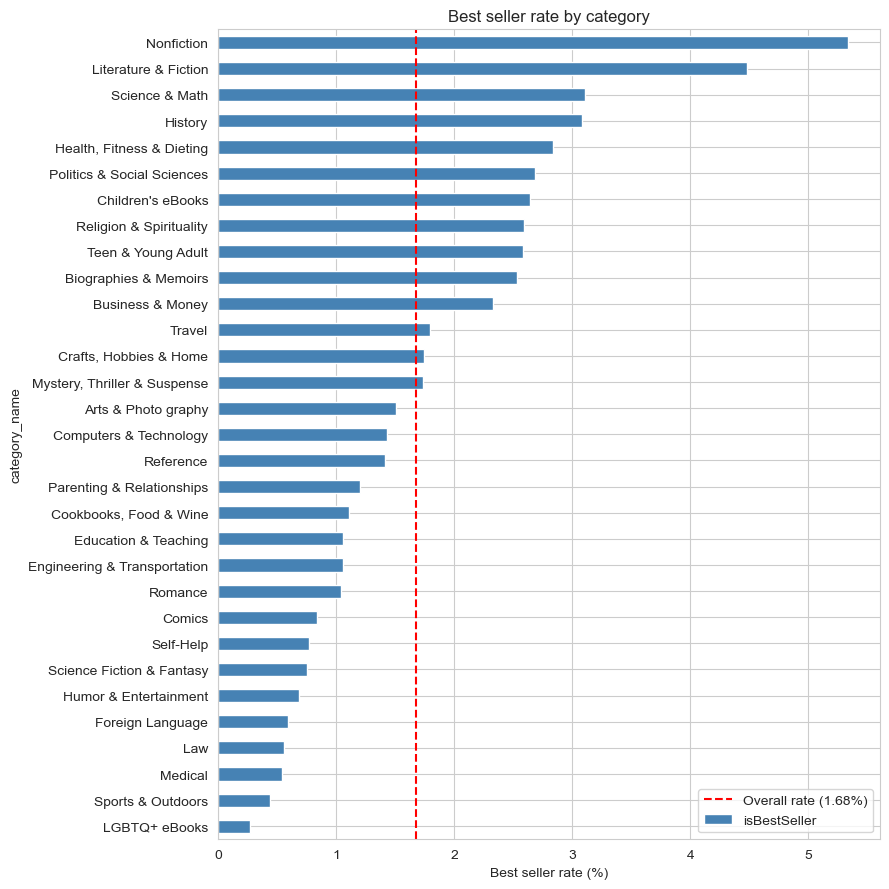

Highest: Nonfiction 5.34 %
Lowest:  LGBTQ+ eBooks 0.27 %


In [16]:
cat_rate = (df_clean.groupby('category_name')['isBestSeller'].mean() * 100).sort_values()
overall = df_clean['isBestSeller'].mean() * 100

plt.figure(figsize=(9, 9))
cat_rate.plot(kind='barh', color='steelblue')
plt.axvline(overall, color='red', linestyle='--', label=f'Overall rate ({overall:.2f}%)')
plt.title('Best seller rate by category')
plt.xlabel('Best seller rate (%)')
plt.legend()
save_fig('05_bestseller_rate_by_category.png')
plt.show()

print('Highest:', cat_rate.idxmax(), round(cat_rate.max(), 2), '%')
print('Lowest: ', cat_rate.idxmin(), round(cat_rate.min(), 2), '%')

This bar chart shows the percentage of best sellers inside each of the 31 categories, with the red dashed line marking the overall rate of 1.68 percent. Nonfiction has the highest rate at 5.34 percent, followed by Literature & Fiction, Science & Math and History, while LGBTQ+ eBooks has the lowest rate at only 0.27 percent. Because the rate changes so much between categories, the category is clearly a useful feature and will be one hot encoded.

Best seller rate by Kindle Unlimited (%):
isKindleUnlimited
0    0.79
1    4.09
Name: isBestSeller, dtype: float64


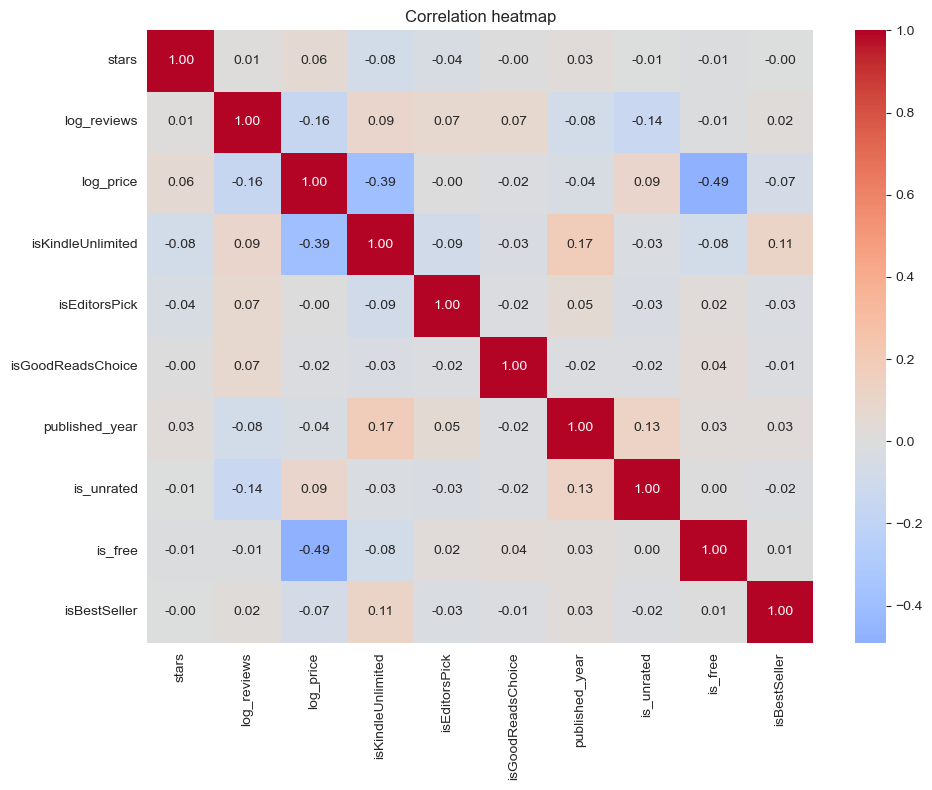

In [17]:
ku_rate = df_clean.groupby('isKindleUnlimited')['isBestSeller'].mean() * 100
print('Best seller rate by Kindle Unlimited (%):')
print(ku_rate.round(2))

corr_cols = ['stars', 'log_reviews', 'log_price', 'isKindleUnlimited', 'isEditorsPick',
             'isGoodReadsChoice', 'published_year', 'is_unrated', 'is_free', 'isBestSeller']
corr = plot_df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
save_fig('06_correlation_heatmap.png')
plt.show()

First we print the best seller rate for Kindle Unlimited books: 4.09 percent of Kindle Unlimited books are best sellers, compared with only 0.79 percent of other books, so being in Kindle Unlimited makes a book about five times more likely to be a best seller. The heatmap then shows how strongly the numeric columns move together. Every correlation with `isBestSeller` is weak; the strongest is Kindle Unlimited at 0.11, followed by log price at about negative 0.07 (cheaper books are slightly more likely to be best sellers). Log price and is_free are strongly related (about negative 0.49) because free books have a price of 0. No two features are so highly correlated that one must be dropped. The weak correlations warn us that predicting best sellers will be hard.

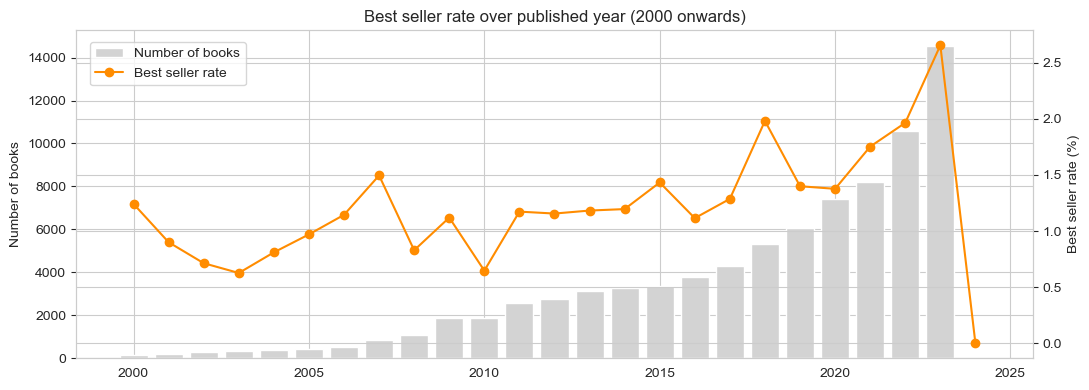

,count,rate_percent
published_year,,
2017.0,4273,1.29
2018.0,5298,1.98
2019.0,6072,1.40
2020.0,7408,1.38
2021.0,8215,1.75
2022.0,10587,1.96
2023.0,14537,2.66
2024.0,1,0.00


In [18]:
year_stats = (df_clean[df_clean['published_year'] >= 2000]
              .groupby('published_year')['isBestSeller'].agg(['mean', 'count']))
year_stats['rate_percent'] = year_stats['mean'] * 100

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(year_stats.index, year_stats['count'], color='lightgrey', label='Number of books')
ax1.set_ylabel('Number of books')
ax2 = ax1.twinx()
ax2.plot(year_stats.index, year_stats['rate_percent'], color='darkorange', marker='o', label='Best seller rate')
ax2.set_ylabel('Best seller rate (%)')
plt.title('Best seller rate over published year (2000 onwards)')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.9))
save_fig('07_bestseller_rate_by_year.png')
plt.show()

year_stats[['count', 'rate_percent']].tail(8).round(2)

This chart shows the number of books published each year since 2000 (grey bars) and the best seller rate for that year (orange line). The rate moves between about 1.3 and 2 percent from 2017 to 2022 but rises to 2.66 percent for books published in 2023, the most recent full year. This makes sense because best seller lists are about current sales, and newer books are more likely to be selling well right now. This supports creating a "book age" feature. The single 2024 book is a preorder and is too small a group to read anything into.

## 4. Target Leakage Check

In [19]:
print('Editors Pick vs Best Seller')
print(pd.crosstab(df_clean['isEditorsPick'], df_clean['isBestSeller']))
print()
print('Goodreads Choice vs Best Seller')
print(pd.crosstab(df_clean['isGoodReadsChoice'], df_clean['isBestSeller']))
print()
both = ((df_clean['isBestSeller'] == 1) & ((df_clean['isEditorsPick'] == 1) | (df_clean['isGoodReadsChoice'] == 1))).sum()
print('Books that are a best seller AND have another badge:', both)

Editors Pick vs Best Seller
isBestSeller        0     1
isEditorsPick              
0              125245  2236
1                5621     0

Goodreads Choice vs Best Seller
isBestSeller            0     1
isGoodReadsChoice              
0                  129464  2236
1                    1402     0

Books that are a best seller AND have another badge: 0


This cell checks the two other badge columns for target leakage. The tables show that not one Editors Pick book and not one Goodreads Choice book is a best seller, and the final line confirms that 0 books have the best seller badge together with another badge. This is not a real pattern about books; it happens because Amazon shows only one badge per listing, so the badges are mutually exclusive by how the website works. If we left these columns in, the model would learn "if it has another badge, it cannot be a best seller", which is information the press would not have before a book is released. These two columns leak information about the target, so they must be removed.

In [20]:
id_cols = ['asin', 'title', 'author', 'soldBy', 'imgUrl', 'productURL', 'category_id', 'category_name']
print(pd.DataFrame({'unique_values': df_clean[id_cols].nunique(),
                    'percent_unique': (df_clean[id_cols].nunique() / len(df_clean) * 100).round(2)}))

# category_id and category_name are the same thing
print()
print('category_id to category_name pairs:', df_clean.groupby(['category_id', 'category_name']).ngroups)

               unique_values  percent_unique
asin                  133102          100.00
title                 131913           99.11
author                 72805           54.70
soldBy                    50            0.04
imgUrl                132909           99.85
productURL            133102          100.00
category_id               31            0.02
category_name             31            0.02

category_id to category_name pairs: 31


This table shows how many unique values each text column has. `asin` and `productURL` are unique for 100 percent of books and `title` and `imgUrl` are unique for more than 99 percent, so these are just identifiers; a model cannot learn a general rule from a value that only appears once. `author` has 72,805 different values, which is far too many to encode and would let the model memorise authors rather than learn patterns. `category_id` and `category_name` form exactly 31 pairs, so they are the same information twice and we only need one. `soldBy` only has 50 values, so it is kept and used to build seller features.

In [21]:
leak_cols = ['isEditorsPick', 'isGoodReadsChoice']
id_drop = ['asin', 'title', 'author', 'imgUrl', 'productURL', 'category_id']

# Keep the title for a couple of engineered features before dropping it
titles = df_clean['title'].copy()
df_model = df_clean.drop(columns=leak_cols + id_drop)
print('Removed:', leak_cols + id_drop)
print('Remaining columns:', list(df_model.columns))

Removed: ['isEditorsPick', 'isGoodReadsChoice', 'asin', 'title', 'author', 'imgUrl', 'productURL', 'category_id']
Remaining columns: ['soldBy', 'stars', 'reviews', 'price', 'isKindleUnlimited', 'isBestSeller', 'publishedDate', 'category_name', 'is_unrated', 'is_free', 'date_missing', 'published_year']


This cell removes the two leaking badge columns and the identifier columns. Before dropping the title we save a copy of it, because the length of a title and whether it is part of a series could still be useful features. The output lists the eight removed columns and the columns that remain for modelling.

## 5. Feature Engineering and Selection

In [22]:
# Decide the training rows now (same split as section 6) so selection never sees the test set
train_idx, test_idx = train_test_split(df_model.index, test_size=0.30,
                                       stratify=df_model['isBestSeller'], random_state=RANDOM_STATE)
print('Training rows:', len(train_idx), ' Test rows:', len(test_idx))

Training rows: 93171  Test rows: 39931


Feature selection must not look at the test data, otherwise the test score would be too optimistic. So before selecting features we decide which rows will be in the training set, using exactly the same stratified 70/30 split and random state that section 6 will use. The output shows 93,171 training rows and 39,931 test rows. Only the training rows are used for filling in missing ages and for the p value selection below.

In [23]:
fe = df_model.copy()

# Log transforms for the very skewed columns
fe['log_reviews'] = np.log1p(fe['reviews'])
fe['log_price'] = np.log1p(fe['price'])

# Book age in years from the newest date in the data
ref_date = fe['publishedDate'].max()
fe['book_age'] = (ref_date - fe['publishedDate']).dt.days / 365.25
fe['book_age'] = fe['book_age'].fillna(fe.loc[train_idx, 'book_age'].median())

# Seller groups
big_five = ['Random House', 'Penguin', 'Hachette', 'HarperCollins', 'Macmillan', 'Simon']
fe['sold_by_amazon'] = (fe['soldBy'] == 'Amazon.com Services LLC').astype(int)
fe['big_five_publisher'] = fe['soldBy'].str.contains('|'.join(big_five), case=False).astype(int)
fe['seller_unknown'] = (fe['soldBy'] == 'Unknown').astype(int)

# Simple title features
fe['title_word_count'] = titles.str.split().str.len()
fe['is_series'] = titles.str.contains(r'Book \d|#\d|Series|Trilogy', case=False, regex=True).astype(int)

# One hot encode category, using the biggest category as the reference
cat_dummies = pd.get_dummies(fe['category_name'], prefix='cat', dtype=int)
cat_dummies = cat_dummies.drop(columns='cat_Mystery, Thriller & Suspense')
fe = pd.concat([fe, cat_dummies], axis=1)

base_features = ['stars', 'is_unrated', 'log_reviews', 'log_price', 'is_free',
                 'isKindleUnlimited', 'book_age', 'date_missing', 'sold_by_amazon',
                 'big_five_publisher', 'seller_unknown', 'title_word_count', 'is_series']
candidate_features = base_features + list(cat_dummies.columns)
print('Number of candidate features:', len(candidate_features))
fe[base_features].describe().T.round(3)

Number of candidate features: 43


,count,mean,std,min,25%,50%,75%,max
stars,133102.0,4.512,0.284,1.0,4.400,4.500,4.700,5.000
is_unrated,133102.0,0.024,0.153,0.0,0.000,0.000,0.000,1.000
log_reviews,133102.0,2.940,3.191,0.0,0.000,1.609,5.903,13.335
log_price,133102.0,2.372,0.859,0.0,1.790,2.397,2.772,6.526
is_free,133102.0,0.031,0.172,0.0,0.000,0.000,0.000,1.000
isKindleUnlimited,133102.0,0.269,0.443,0.0,0.000,0.000,1.000,1.000
book_age,133102.0,5.341,4.821,0.0,3.036,4.255,5.793,218.037
date_missing,133102.0,0.368,0.482,0.0,0.000,0.000,1.000,1.000
sold_by_amazon,133102.0,0.637,0.481,0.0,0.000,1.000,1.000,1.000
big_five_publisher,133102.0,0.241,0.427,0.0,0.000,0.000,0.000,1.000


This cell creates the new features. Reviews and price are log transformed with `log1p` to shrink their long tails. `book_age` is the number of years between a book's published date and the newest date in the data, and missing ages are filled with the median age from the training rows only. Three seller flags are created: sold by Amazon (mostly self published books), sold by one of the Big Five publishers, and unknown seller. From the title we count the number of words and flag books that look like part of a series. Finally the category is one hot encoded, with the largest category (Mystery, Thriller & Suspense) left out as the reference group so the dummies are not perfectly collinear. This gives 43 candidate features, and the summary table shows their ranges; for example the average book is about 5.3 years old and 27 percent are in Kindle Unlimited.

In [24]:
X_sel = sm.add_constant(fe.loc[train_idx, candidate_features].astype(float))
y_sel = fe.loc[train_idx, 'isBestSeller']

remaining = candidate_features.copy()
decisions = []
step = 0

# Backward elimination: drop the least significant feature until all p values are below 0.05
while True:
    model = sm.Logit(y_sel, X_sel[['const'] + remaining]).fit(disp=0, maxiter=200)
    pvals = model.pvalues.drop('const')
    worst = pvals.idxmax()
    if pvals[worst] <= 0.05:
        break
    step += 1
    decisions.append({'feature': worst, 'p_value': round(pvals[worst], 4),
                      'step_removed': step, 'decision': 'Removed (p > 0.05)'})
    remaining.remove(worst)

final_model = model
for f in remaining:
    decisions.append({'feature': f, 'p_value': round(final_model.pvalues[f], 4),
                      'step_removed': '', 'decision': 'Kept (p <= 0.05)'})

decision_table = pd.DataFrame(decisions)
print('Features removed:', step, ' Features kept:', len(remaining))
decision_table

Features removed: 10  Features kept: 33


,feature,p_value,step_removed,decision
0,big_five_publisher,0.8771,1,Removed (p > 0.05)
1,cat_Law,0.6916,2,Removed (p > 0.05)
2,cat_Medical,0.5712,3,Removed (p > 0.05)
3,cat_Comics,0.5111,4,Removed (p > 0.05)
4,cat_Parenting & Relationships,0.4317,5,Removed (p > 0.05)
5,log_reviews,0.3378,6,Removed (p > 0.05)
6,cat_Foreign Language,0.2737,7,Removed (p > 0.05)
7,stars,0.2141,8,Removed (p > 0.05)
8,cat_Self-Help,0.2283,9,Removed (p > 0.05)
9,cat_Romance,0.0580,10,Removed (p > 0.05)


This cell performs backward elimination. A statsmodels Logit model is fitted on the training rows with all 43 candidates, the feature with the highest p value is found, and if that p value is above 0.05 the feature is removed and the model is refitted. This repeats until every remaining feature is significant. The decision table shows that 10 features were removed and 33 were kept. The first to go was `big_five_publisher` (p value 0.88), followed by several categories that behave like the reference category (Law, Medical, Comics, Parenting & Relationships, Foreign Language, Romance). Interestingly `log_reviews` (p value 0.34) and `stars` (p value 0.21) were also removed, which matches the EDA: star ratings are almost the same for best sellers and other books, and the review count is unreliable because it was not collected for many categories.

In [25]:
print(final_model.summary2().tables[1].round(4))
final_features = remaining

                                   Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
const                            -3.8645    0.1675 -23.0760  0.0000 -4.1927 -3.5363
is_unrated                       -2.4155    0.5810  -4.1578  0.0000 -3.5542 -1.2768
log_price                        -0.6504    0.0491 -13.2389  0.0000 -0.7467 -0.5541
is_free                          -0.5456    0.1851  -2.9474  0.0032 -0.9084 -0.1828
isKindleUnlimited                 1.9717    0.0739  26.6870  0.0000  1.8269  2.1165
book_age                         -0.0208    0.0073  -2.8609  0.0042 -0.0351 -0.0066
date_missing                     -0.3063    0.0703  -4.3580  0.0000 -0.4441 -0.1686
sold_by_amazon                   -0.5725    0.0808  -7.0866  0.0000 -0.7308 -0.4141
seller_unknown                   -1.4084    0.2641  -5.3324  0.0000 -1.9260 -0.8907
title_word_count                  0.0374    0.0042   8.8272  0.0000  0.0291  0.0457
is_series                        -0.5702    0.0804  -7.0901  0.0000 -0.7279 

This is the coefficient table of the final statsmodels Logit model with the 33 kept features, and every p value is below 0.05. The strongest positive effect is Kindle Unlimited with a coefficient of about 1.97 and a very large z value of 26.7, which makes it the most reliable predictor. Price has a negative coefficient (about 0.65 below zero), meaning more expensive books are less likely to be best sellers. Being unrated, part of a series, sold by Amazon or having an unknown seller also lower the chance. The list of kept features is stored as `final_features`.

## 6. Train/Test Split and Scaling

In [26]:
X = fe[final_features].astype(float)
y = fe['isBestSeller'].astype(int)

# Stratified 70/30 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y,
                                                    random_state=RANDOM_STATE)

# Check it matches the rows used for feature selection
print('Same training rows as section 5:', set(X_train.index) == set(train_idx))
print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('Best seller rate train:', round(y_train.mean() * 100, 2), '%   test:', round(y_test.mean() * 100, 2), '%')

Same training rows as section 5: True
X_train: (93171, 33)  X_test: (39931, 33)
Best seller rate train: 1.68 %   test: 1.68 %


Here we build the final feature matrix `X` and the target `y` and split them 70/30. Using `stratify=y` makes sure both sets keep the same share of best sellers, and the output confirms the rate is 1.68 percent in both the training and the test set. The first line confirms the training rows are exactly the same as the ones used for feature selection, so the test set has never been seen. The training set has 93,171 books and the test set has 39,931 books, each with 33 features.

In [27]:
# Fit the scaler on the training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_np = y_train.values
y_test_np = y_test.values

print('Train means (first 5):', X_train_scaled.mean(axis=0)[:5].round(3))
print('Train std   (first 5):', X_train_scaled.std(axis=0)[:5].round(3))
print('Test means  (first 5):', X_test_scaled.mean(axis=0)[:5].round(3))

Train means (first 5): [-0. -0.  0. -0.  0.]
Train std   (first 5): [1. 1. 1. 1. 1.]
Test means  (first 5): [-0.002 -0.002  0.009 -0.01  -0.001]


Just like the `normalize` function in our class notebook, we scale each feature to have a mean of 0 and a standard deviation of 1, so that features measured in large units (like book age) do not dominate small ones and gradient descent converges smoothly. The important difference is that the `StandardScaler` is fitted only on the training data and then applied to the test data, so no information from the test set leaks into training. The output shows the training means are 0 and the standard deviations are 1, while the test means are very close to 0 but not exactly, which is what we expect.

## 7. Logistic Regression From Scratch

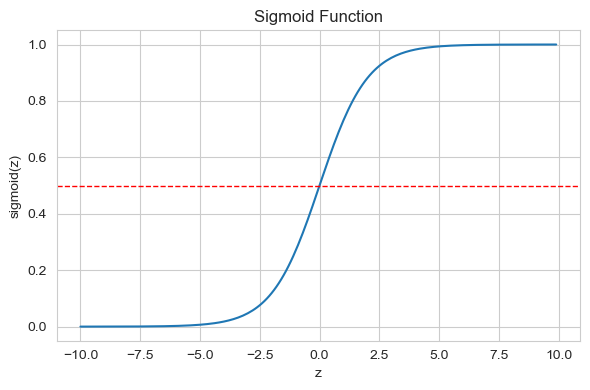

In [28]:
def sigmoid(z):
    # Clip to avoid overflow in exp
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

X_demo = np.arange(-10, 10, 0.1)
plt.figure(figsize=(6, 4))
plt.plot(X_demo, sigmoid(X_demo))
plt.axhline(0.5, color='red', linestyle='--', linewidth=1)
plt.title('Sigmoid Function')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
save_fig('08_sigmoid.png')
plt.show()

This is the same sigmoid function from the class notebook, with one small improvement: the input is clipped so that very large numbers cannot cause an overflow error in `np.exp`. The sigmoid squashes any number into a value between 0 and 1, which we read as the probability that a book is a best seller. The plot shows the familiar S shape, and the red dashed line marks 0.5, the default point where we switch from predicting "not a best seller" to "best seller".

In [29]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, n_iterations=1000, class_weight=None,
                 l2_lambda=0.0, threshold=0.5, random_state=42):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.class_weight = class_weight
        self.l2_lambda = l2_lambda
        self.threshold = threshold
        self.random_state = random_state

    def _sample_weights(self, y):
        # Balanced weights give the rare class a bigger say in the cost
        if self.class_weight == 'balanced':
            n, n_pos = len(y), y.sum()
            w_pos = n / (2 * n_pos)
            w_neg = n / (2 * (n - n_pos))
            return np.where(y == 1, w_pos, w_neg)
        return np.ones(len(y))

    def compute_cost(self, X, y, sample_weights):
        # Weighted log loss plus the L2 penalty
        m = len(y)
        p = np.clip(sigmoid(X @ self.weights + self.bias), 1e-15, 1 - 1e-15)
        log_loss = -np.sum(sample_weights * (y * np.log(p) + (1 - y) * np.log(1 - p))) / m
        l2_penalty = (self.l2_lambda / (2 * m)) * np.sum(self.weights ** 2)
        return log_loss + l2_penalty

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        m, n = X.shape

        # Small random starting weights, like in class
        rng = np.random.RandomState(self.random_state)
        self.weights = rng.randn(n) * 0.01
        self.bias = 0.0

        sample_weights = self._sample_weights(y)
        self.cost_history = []

        for i in range(self.n_iterations):
            # Forward pass
            z = X @ self.weights + self.bias
            predicted = sigmoid(z)

            # Gradients of the cost
            error = sample_weights * (predicted - y)
            dw = (X.T @ error) / m + (self.l2_lambda / m) * self.weights
            db = np.sum(error) / m

            # Gradient descent update
            self.weights = self.weights - self.learning_rate * dw
            self.bias = self.bias - self.learning_rate * db

            self.cost_history.append(self.compute_cost(X, y, sample_weights))
        return self

    def predict_proba(self, X):
        return sigmoid(np.asarray(X, dtype=float) @ self.weights + self.bias)

    def predict(self, X, threshold=None):
        t = self.threshold if threshold is None else threshold
        return (self.predict_proba(X) >= t).astype(int)

This cell builds the logistic regression from scratch as a class so it can be reused for every experiment. The `fit` method starts with small random weights (like `np.random.randn()` in class), then repeats three steps for every iteration: it calculates the predicted probabilities with the sigmoid, works out the gradients of the cost with respect to the weights and bias, and moves the weights a small step against the gradient (gradient descent). There are two improvements over the class notebook. First, the cost is log loss (cross entropy) instead of squared error, because log loss is the correct cost for probabilities and gives a smooth bowl shaped surface with one minimum. Second, the class uses the whole training set in each step (batch gradient descent) instead of one random person at a time, which gives a much smoother cost curve. The class also supports optional class weights, an L2 penalty and a custom decision threshold, which we will use in section 9. `predict_proba` returns probabilities and `predict` turns them into 0 or 1 using the threshold.

In [30]:
base_model = LogisticRegressionScratch(learning_rate=0.1, n_iterations=2000, random_state=RANDOM_STATE)
base_model.fit(X_train_scaled, y_train_np)

print('Starting cost:', round(base_model.cost_history[0], 5))
print('Final cost:   ', round(base_model.cost_history[-1], 5))
print('Bias:', round(base_model.bias, 4))

Starting cost: 0.67019
Final cost:    0.07337
Bias: -4.3642


We train the first version of the model with a learning rate of 0.1 for 2,000 iterations and no extra settings. The cost starts at 0.670, which is about what you get when every prediction is 0.5, and falls to 0.073, so the model has clearly learned something. The bias ends at about 4.36 below zero, which pushes every prediction towards a very small probability because best sellers are so rare.

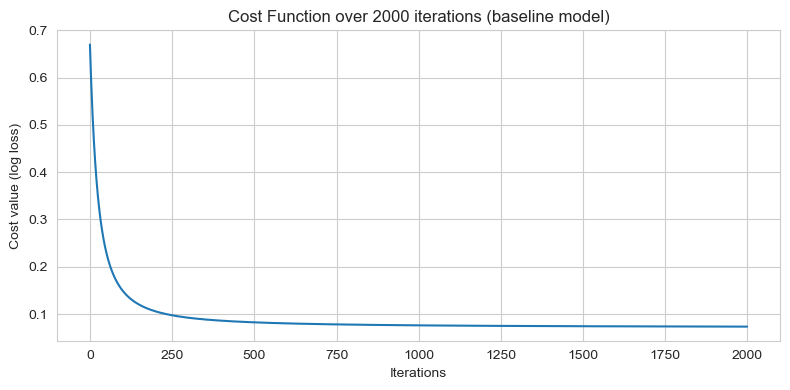

In [31]:
plt.figure(figsize=(8, 4))
plt.plot(base_model.cost_history)
plt.title('Cost Function over 2000 iterations (baseline model)')
plt.xlabel('Iterations')
plt.ylabel('Cost value (log loss)')
save_fig('09_cost_baseline.png')
plt.show()

This plot of cost over iterations is the same kind of chart as in the class notebook. The cost drops very quickly in the first few hundred iterations and then flattens out, which shows gradient descent is converging to a minimum. The curve is smooth (unlike the jumpy curve in class) because each step uses all the training books instead of one random example.

## 8. Evaluation

In [32]:
def evaluate(y_true, y_pred, y_prob, name):
    return {'model': name,
            'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred),
            'roc_auc': roc_auc_score(y_true, y_prob),
            'pr_auc': average_precision_score(y_true, y_prob)}

base_prob = base_model.predict_proba(X_test_scaled)
base_pred = base_model.predict(X_test_scaled)

# Dummy baseline: always say "not a best seller"
dummy_pred = np.zeros(len(y_test_np), dtype=int)
dummy_prob = np.zeros(len(y_test_np))

results_8 = pd.DataFrame([evaluate(y_test_np, dummy_pred, dummy_prob, 'Always predict not best seller'),
                          evaluate(y_test_np, base_pred, base_prob, 'Scratch LR baseline (threshold 0.5)')])
results_8.round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Always predict not best seller,0.9832,0.0,0.0,0.0,0.5000,0.0168
1,Scratch LR baseline (threshold 0.5),0.9832,0.0,0.0,0.0,0.8073,0.0706


The `evaluate` function calculates six metrics, and we compare the baseline model with a "dummy" model that always predicts "not a best seller". Both get an accuracy of 98.32 percent, and both have precision, recall and F1 of 0, because the scratch model never predicts a best seller at the 0.5 threshold. This is exactly why accuracy alone is misleading on imbalanced data: a model can look excellent while finding none of the books we actually care about. The ROC AUC tells a better story. The scratch model scores 0.807 against 0.5 for the dummy, which means it does rank best sellers higher than other books; its PR AUC of 0.071 is also about four times the 0.017 a random guess would get. The problem is not that the model learned nothing, it is that the 0.5 threshold is far too high for such a rare class.

[[39260     0]
 [  671     0]]


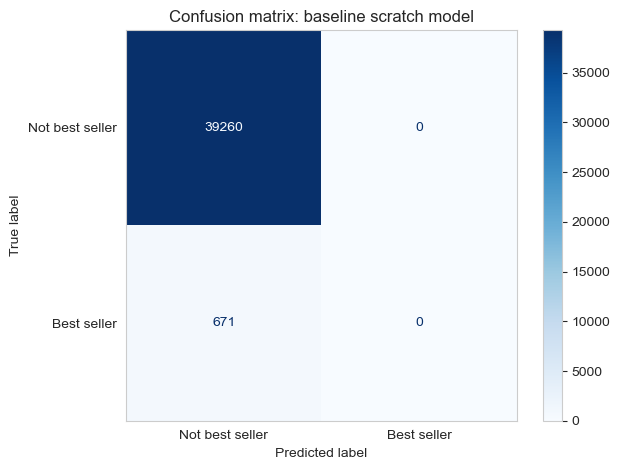

In [33]:
cm = confusion_matrix(y_test_np, base_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['Not best seller', 'Best seller']).plot(cmap='Blues', values_format='d')
plt.title('Confusion matrix: baseline scratch model')
plt.grid(False)
save_fig('10_confusion_matrix_baseline.png')
plt.show()

The confusion matrix confirms the problem. All 39,260 non best sellers are correctly predicted, but all 671 real best sellers in the test set are missed, so there are 0 true positives. For the book press, this model would never recommend a single book, which is useless no matter how high the accuracy is.

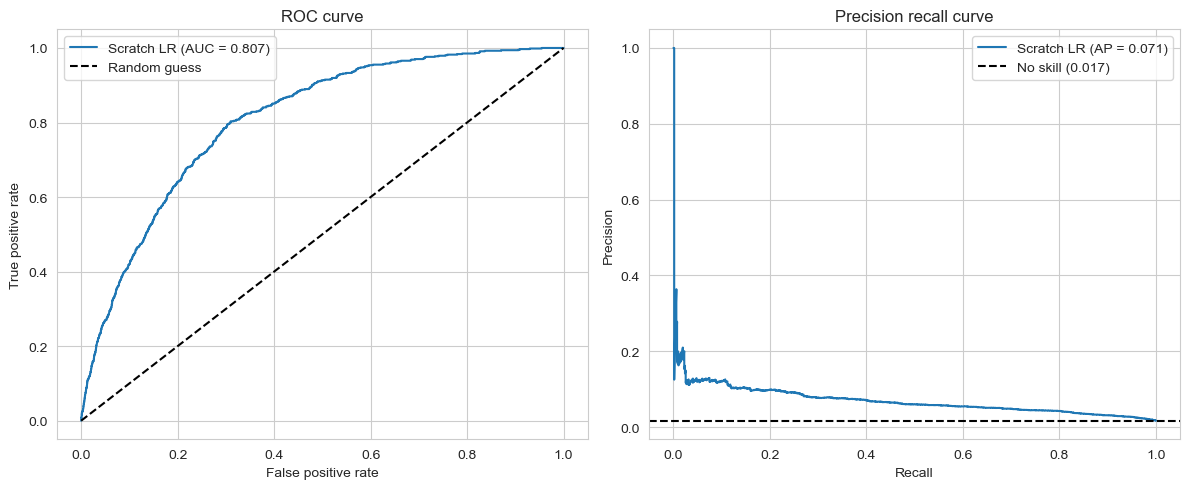

In [34]:
fpr, tpr, _ = roc_curve(y_test_np, base_prob)
prec, rec, _ = precision_recall_curve(y_test_np, base_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f'Scratch LR (AUC = {roc_auc_score(y_test_np, base_prob):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[0].set_title('ROC curve')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].legend()

axes[1].plot(rec, prec, label=f'Scratch LR (AP = {average_precision_score(y_test_np, base_prob):.3f})')
axes[1].axhline(y_test_np.mean(), color='k', linestyle='--', label=f'No skill ({y_test_np.mean():.3f})')
axes[1].set_title('Precision recall curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
save_fig('11_roc_pr_baseline.png')
plt.show()

The ROC curve (left) plots the true positive rate against the false positive rate at every possible threshold. Our curve sits well above the diagonal random guess line, with an AUC of about 0.81, so the model separates the classes reasonably well. The precision recall curve (right) is more honest for rare classes. The dashed line at 0.017 is what random guessing gives, and our curve is above it everywhere, but it stays low, with a PR AUC of only about 0.07, so most books the model flags will not be real best sellers. This shows there is useful signal, but best sellers are genuinely hard to pick out from these features.

## 9. Retraining to Fix the Weaknesses

In [35]:
# Validation set taken from the training data, used only for tuning
X_sub, X_val, y_sub, y_val = train_test_split(X_train_scaled, y_train_np, test_size=0.20,
                                              stratify=y_train_np, random_state=RANDOM_STATE)
print('Sub train:', X_sub.shape, ' Validation:', X_val.shape)


def best_threshold(y_true, y_prob):
    # Pick the threshold that gives the highest F1 on validation
    thresholds = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    return round(thresholds[int(np.argmax(scores))], 2), max(scores)

Sub train: (74536, 33)  Validation: (18635, 33)


To tune settings fairly, we split the scaled training set again into a sub training set (80 percent, 74,536 books) and a validation set (20 percent, 18,635 books). Every tuning decision in this section is made on the validation set, so the test set stays untouched until the final comparison. The helper function `best_threshold` tries every threshold from 0.05 to 0.95 and returns the one with the highest F1 score.

In [36]:
# Version 2: class weights in the cost function
cw_val = LogisticRegressionScratch(learning_rate=0.1, n_iterations=2000, class_weight='balanced').fit(X_sub, y_sub)
cw_val_prob = cw_val.predict_proba(X_val)
print('Validation F1 at 0.5, no weights:  ', round(f1_score(y_val, LogisticRegressionScratch(learning_rate=0.1, n_iterations=2000).fit(X_sub, y_sub).predict(X_val)), 4))
print('Validation F1 at 0.5, with weights:', round(f1_score(y_val, (cw_val_prob >= 0.5).astype(int)), 4))
print('Validation recall at 0.5, with weights:', round(recall_score(y_val, (cw_val_prob >= 0.5).astype(int)), 4))

Validation F1 at 0.5, no weights:   0.0
Validation F1 at 0.5, with weights: 0.0925
Validation recall at 0.5, with weights: 0.7476


The first fix is class weights in the cost function. With `class_weight='balanced'`, each best seller counts about 58 times more than a normal book in the log loss, so the model is punished much more for missing one. Without weights the validation F1 at the 0.5 threshold is 0, but with weights it rises to 0.093 and recall jumps to 0.75, meaning the model now finds three quarters of the best sellers. The catch is that it also flags many books that are not best sellers, so precision becomes very low.

Best threshold (class weights): 0.84  validation F1: 0.1585


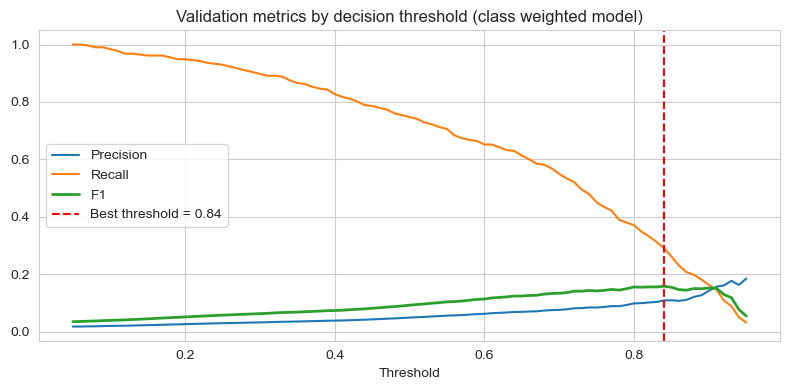

In [37]:
# Version 3: tune the decision threshold on validation
t_cw, f1_cw = best_threshold(y_val, cw_val_prob)
print('Best threshold (class weights):', t_cw, ' validation F1:', round(f1_cw, 4))

thresholds = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_val, (cw_val_prob >= t).astype(int), zero_division=0) for t in thresholds]
precs = [precision_score(y_val, (cw_val_prob >= t).astype(int), zero_division=0) for t in thresholds]
recs = [recall_score(y_val, (cw_val_prob >= t).astype(int)) for t in thresholds]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precs, label='Precision')
plt.plot(thresholds, recs, label='Recall')
plt.plot(thresholds, f1s, label='F1', linewidth=2)
plt.axvline(t_cw, color='red', linestyle='--', label=f'Best threshold = {t_cw}')
plt.title('Validation metrics by decision threshold (class weighted model)')
plt.xlabel('Threshold')
plt.legend()
save_fig('12_threshold_tuning.png')
plt.show()

The second fix is tuning the decision threshold. Class weights push all probabilities upwards, so 0.5 is now too low and too many books are flagged. The chart shows that as the threshold rises, precision goes up and recall goes down, and F1 (their balance) peaks at a threshold of 0.84, where the validation F1 is 0.159. This is a big improvement over 0.093 at the 0.5 threshold.

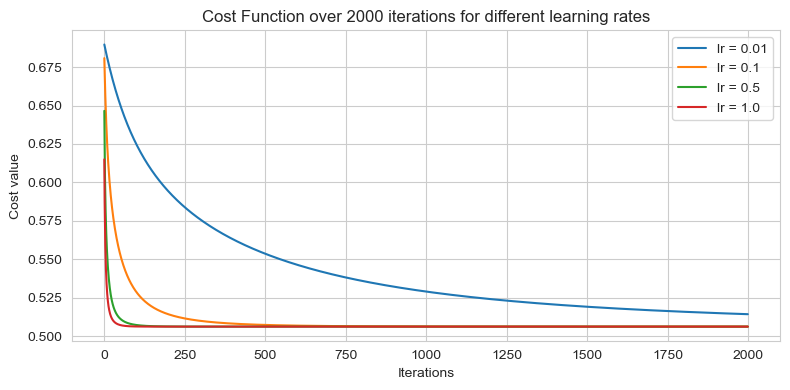

Chosen learning rate: 1.0


,learning_rate,final_train_cost,val_roc_auc,best_threshold,val_f1
0,0.01,0.5144,0.8248,0.88,0.1564
1,0.10,0.5063,0.8258,0.84,0.1585
2,0.50,0.5063,0.8256,0.84,0.1583
3,1.00,0.5063,0.8256,0.84,0.1583


In [38]:
# Version 4: try different learning rates
lr_results = []
plt.figure(figsize=(8, 4))
for lr in [0.01, 0.1, 0.5, 1.0]:
    m_lr = LogisticRegressionScratch(learning_rate=lr, n_iterations=2000, class_weight='balanced').fit(X_sub, y_sub)
    p_val = m_lr.predict_proba(X_val)
    t, f1v = best_threshold(y_val, p_val)
    lr_results.append({'learning_rate': lr, 'final_train_cost': m_lr.cost_history[-1],
                       'val_roc_auc': roc_auc_score(y_val, p_val), 'best_threshold': t, 'val_f1': f1v})
    plt.plot(m_lr.cost_history, label=f'lr = {lr}')
plt.title('Cost Function over 2000 iterations for different learning rates')
plt.xlabel('Iterations')
plt.ylabel('Cost value')
plt.legend()
save_fig('13_learning_rates.png')
plt.show()

lr_table = pd.DataFrame(lr_results)
best_lr = lr_table.loc[lr_table['final_train_cost'].idxmin(), 'learning_rate']
print('Chosen learning rate:', best_lr)
lr_table.round(4)

The third fix is the learning rate. We train the weighted model with learning rates of 0.01, 0.1, 0.5 and 1.0. The cost chart shows that 0.01 is far too slow and is still coming down after 2,000 iterations (final cost 0.514), while 0.1, 0.5 and 1.0 all finish at the lowest cost of 0.506. The chart shows that 0.5 and 1.0 get there in far fewer iterations, so a learning rate of 1.0 is chosen because it reaches the minimum fastest. The validation F1 barely changes (about 0.158 for all except 0.01), which tells us the learning rate mainly controls how fast we reach the answer, not the answer itself.

In [39]:
# Version 5: add L2 regularisation
l2_results = []
for lam in [0, 10, 100, 1000, 10000, 50000]:
    m_l2 = LogisticRegressionScratch(learning_rate=best_lr, n_iterations=2000, class_weight='balanced',
                                     l2_lambda=lam).fit(X_sub, y_sub)
    p_val = m_l2.predict_proba(X_val)
    t, f1v = best_threshold(y_val, p_val)
    l2_results.append({'l2_lambda': lam, 'val_roc_auc': roc_auc_score(y_val, p_val),
                       'val_pr_auc': average_precision_score(y_val, p_val),
                       'best_threshold': t, 'val_f1': f1v,
                       'sum_abs_weights': np.abs(m_l2.weights).sum()})

l2_table = pd.DataFrame(l2_results)
# Best non zero lambda so the L2 version is a real change
l2_nonzero = l2_table[l2_table['l2_lambda'] > 0]
best_lambda = l2_nonzero.loc[l2_nonzero['val_f1'].idxmax(), 'l2_lambda']
t_l2 = l2_nonzero.loc[l2_nonzero['val_f1'].idxmax(), 'best_threshold']
print('Chosen lambda:', best_lambda, ' threshold:', t_l2)
l2_table.round(4)

Chosen lambda: 10  threshold: 0.84


,l2_lambda,val_roc_auc,val_pr_auc,best_threshold,val_f1,sum_abs_weights
0,0,0.8256,0.0896,0.84,0.1583,7.9091
1,10,0.8257,0.0896,0.84,0.1590,7.8831
2,100,0.8259,0.0899,0.84,0.1573,7.6650
3,1000,0.8259,0.0906,0.81,0.1571,6.2680
4,10000,0.8182,0.0875,0.75,0.1580,3.0262
5,50000,0.8012,0.0774,0.62,0.1540,1.1950


The fourth fix is L2 regularisation, which adds a penalty for large weights to the cost so the model is less likely to overfit. We try six lambda values. As lambda grows, the total size of the weights shrinks from 7.9 to 1.2, which proves the penalty is working. However, the validation scores hardly move for small lambdas and get worse for very large ones (ROC AUC falls to 0.80 at lambda 50,000). The best non zero value is lambda 10 with a validation F1 of 0.159. Regularisation does not help much here because we have over 74,000 training books and only 33 features, so the model was not overfitting in the first place.

In [40]:
# Retrain every version on the full training set and score on the test set
t_lr = lr_table.loc[lr_table['learning_rate'] == best_lr, 'best_threshold'].values[0]
versions = [
    ('V1 Baseline (lr 0.1, t 0.5)',        dict(learning_rate=0.1), 0.5),
    ('V2 Class weights (t 0.5)',            dict(learning_rate=0.1, class_weight='balanced'), 0.5),
    ('V3 Class weights + tuned threshold',  dict(learning_rate=0.1, class_weight='balanced'), t_cw),
    (f'V4 + learning rate {best_lr}',       dict(learning_rate=best_lr, class_weight='balanced'), t_lr),
    (f'V5 + L2 (lambda {best_lambda})',     dict(learning_rate=best_lr, class_weight='balanced', l2_lambda=best_lambda), t_l2),
]

rows, fitted = [], {}
for name, params, thr in versions:
    # Validation score (trained on sub train) is used to pick the winner
    m_val = LogisticRegressionScratch(n_iterations=2000, random_state=RANDOM_STATE, **params).fit(X_sub, y_sub)
    val_f1 = f1_score(y_val, m_val.predict(X_val, thr))
    # Final model trained on the full training set and scored on test
    m = LogisticRegressionScratch(n_iterations=2000, random_state=RANDOM_STATE, **params).fit(X_train_scaled, y_train_np)
    prob = m.predict_proba(X_test_scaled)
    row = evaluate(y_test_np, (prob >= thr).astype(int), prob, name)
    row['threshold'] = thr
    row['val_f1'] = val_f1
    rows.append(row)
    fitted[name] = (m, thr)

rows.insert(0, evaluate(y_test_np, dummy_pred, dummy_prob, 'Always predict not best seller'))
comparison = pd.DataFrame(rows).set_index('model')
comparison.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,val_f1
model,,,,,,,,
Always predict not best seller,0.9832,0.0000,0.0000,0.0000,0.5000,0.0168,NaN,NaN
"V1 Baseline (lr 0.1, t 0.5)",0.9832,0.0000,0.0000,0.0000,0.8073,0.0706,0.50,0.0000
V2 Class weights (t 0.5),0.7461,0.0465,0.7243,0.0875,0.8078,0.0656,0.50,0.0925
V3 Class weights + tuned threshold,0.9451,0.0819,0.2221,0.1196,0.8078,0.0656,0.84,0.1585
V4 + learning rate 1.0,0.9450,0.0817,0.2221,0.1195,0.8078,0.0656,0.84,0.1583
V5 + L2 (lambda 10),0.9451,0.0819,0.2221,0.1197,0.8078,0.0656,0.84,0.1590


This table retrains every version on the full training set and scores it on the test set, and the `val_f1` column shows the validation score used to choose the winner. The dummy model and V1 have the highest accuracy (98.32 percent) but an F1 of 0, so they are useless. V2 (class weights only) finds 72 percent of best sellers but accuracy drops to 74.6 percent because it flags far too many books. V3, V4 and V5 (class weights plus a tuned threshold of 0.84) give the best balance, with an F1 of about 0.12, recall of 0.22 and precision of 0.08 on the test set. V4 and V5 are almost identical to V3, which agrees with what we saw above: the learning rate and L2 only changed the speed and size of the weights, while class weights and the threshold were the changes that really mattered. The ROC AUC is about 0.81 for every version, because these fixes change where we draw the line, not how well the model ranks books.

Best version: V5 + L2 (lambda 10)  threshold: 0.84


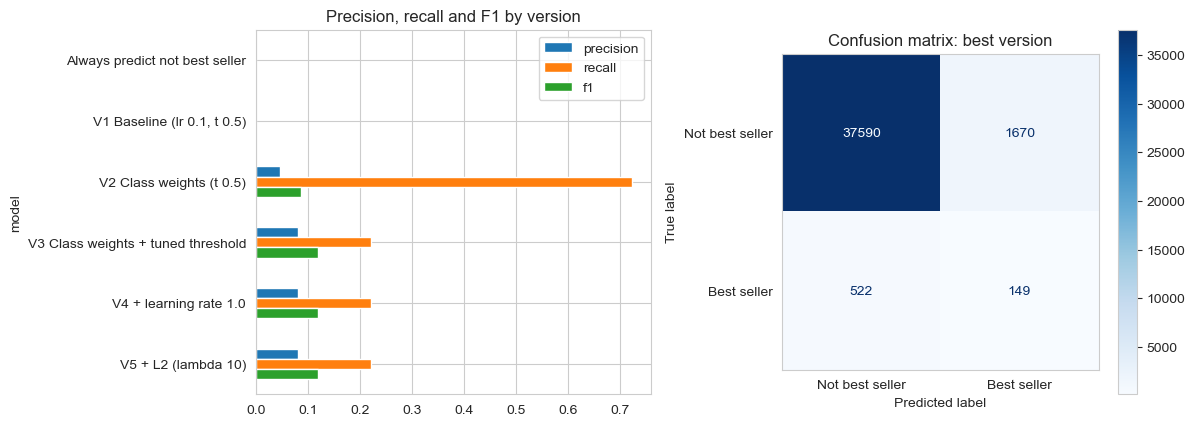

In [41]:
# Best version = highest VALIDATION F1, so the test set is not used for choosing
best_name = comparison.drop('Always predict not best seller')['val_f1'].idxmax()
best_model, best_t = fitted[best_name]
best_prob = best_model.predict_proba(X_test_scaled)
best_pred = (best_prob >= best_t).astype(int)
print('Best version:', best_name, ' threshold:', best_t)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison[['precision', 'recall', 'f1']].plot(kind='barh', ax=axes[0])
axes[0].set_title('Precision, recall and F1 by version')
axes[0].invert_yaxis()
ConfusionMatrixDisplay(confusion_matrix(y_test_np, best_pred),
                       display_labels=['Not best seller', 'Best seller']).plot(ax=axes[1], cmap='Blues', values_format='d')
axes[1].set_title('Confusion matrix: best version')
axes[1].grid(False)
save_fig('14_version_comparison.png')
plt.show()

The best version is chosen by the highest validation F1, not the test F1, so the test set is never used to make a choice. The winner is V5 (class weights, learning rate 1.0, L2 lambda 10 and threshold 0.84). The bar chart compares precision, recall and F1 for all versions, and the confusion matrix for the best version shows it correctly finds 149 of the 671 best sellers in the test set (recall 22 percent), while incorrectly flagging about 1,670 other books. This is a big step up from the baseline, which found none.

## 10. Comparison with scikit learn

In [42]:
# Match the scratch cost: C = 1 / lambda, and no penalty when lambda is 0
sk_params = dict(class_weight=best_model.class_weight, solver='lbfgs', max_iter=5000, tol=1e-10,
                 random_state=RANDOM_STATE)
if best_model.l2_lambda > 0:
    sk_model = LogisticRegression(C=1 / best_model.l2_lambda, **sk_params)
else:
    sk_model = LogisticRegression(penalty=None, **sk_params)
sk_model.fit(X_train_scaled, y_train_np)

sk_prob = sk_model.predict_proba(X_test_scaled)[:, 1]
sk_pred = (sk_prob >= best_t).astype(int)

sk_compare = pd.DataFrame([evaluate(y_test_np, best_pred, best_prob, 'Scratch (best version)'),
                           evaluate(y_test_np, sk_pred, sk_prob, 'scikit learn LogisticRegression')]).set_index('model')
print('Correlation of predicted probabilities:', round(np.corrcoef(best_prob, sk_prob)[0, 1], 6))
print('Largest probability difference:      ', round(np.abs(best_prob - sk_prob).max(), 6))
print('Predictions that agree:               ', round((best_pred == sk_pred).mean() * 100, 3), '%')
sk_compare.round(4)

Correlation of predicted probabilities: 1.0
Largest probability difference:       0.0
Predictions that agree:                100.0 %


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Scratch (best version),0.9451,0.0819,0.2221,0.1197,0.8078,0.0656
scikit learn LogisticRegression,0.9451,0.0819,0.2221,0.1197,0.8078,0.0656


To prove our from scratch code is correct, we train scikit learn's `LogisticRegression` with exactly the same settings: the same balanced class weights, and `C = 1 / lambda` so that its L2 penalty matches ours. The two models give identical results: the predicted probabilities have a correlation of 1.0, the largest difference between any two probabilities is 0.0 (to six decimal places), 100 percent of predictions agree, and every metric in the table is the same. This shows that our sigmoid, cost function and gradient descent are implemented correctly.

Largest coefficient difference: 0.0


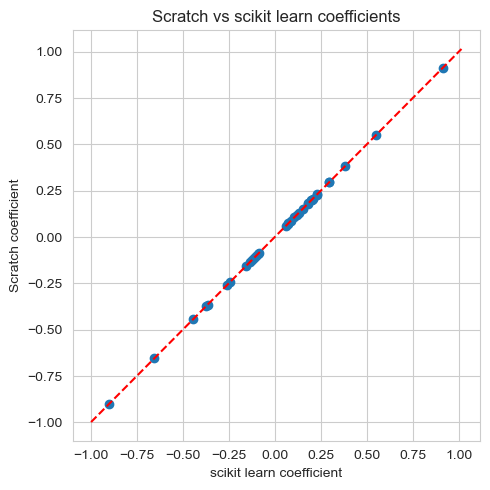

,scratch,sklearn,difference
is_unrated,-0.3709,-0.3709,0.0
log_price,-0.6543,-0.6543,-0.0
is_free,-0.1227,-0.1227,0.0
isKindleUnlimited,0.9154,0.9154,-0.0
book_age,-0.1329,-0.1329,-0.0
date_missing,-0.1555,-0.1555,0.0
sold_by_amazon,-0.2423,-0.2423,-0.0
seller_unknown,-0.3643,-0.3643,-0.0
title_word_count,0.2273,0.2273,0.0
is_series,-0.2568,-0.2568,-0.0


In [43]:
coef_compare = pd.DataFrame({'scratch': best_model.weights, 'sklearn': sk_model.coef_[0]}, index=final_features)
coef_compare.loc['bias (intercept)'] = [best_model.bias, sk_model.intercept_[0]]
coef_compare['difference'] = coef_compare['scratch'] - coef_compare['sklearn']
print('Largest coefficient difference:', round(coef_compare['difference'].abs().max(), 5))

plt.figure(figsize=(5, 5))
plt.scatter(coef_compare['sklearn'], coef_compare['scratch'])
lims = [coef_compare[['scratch', 'sklearn']].min().min() - 0.1, coef_compare[['scratch', 'sklearn']].max().max() + 0.1]
plt.plot(lims, lims, 'r--')
plt.xlabel('scikit learn coefficient')
plt.ylabel('Scratch coefficient')
plt.title('Scratch vs scikit learn coefficients')
save_fig('15_scratch_vs_sklearn.png')
plt.show()

coef_compare.round(4)

As a final check we place the weights from both models side by side. The largest difference across all 33 coefficients and the bias is 0.0 to five decimal places, and in the scatter plot every point lies exactly on the red line where the two models agree perfectly. Our hand written gradient descent has reached the same minimum of the cost function as scikit learn's optimiser.

## 11. Interpreting the Coefficients

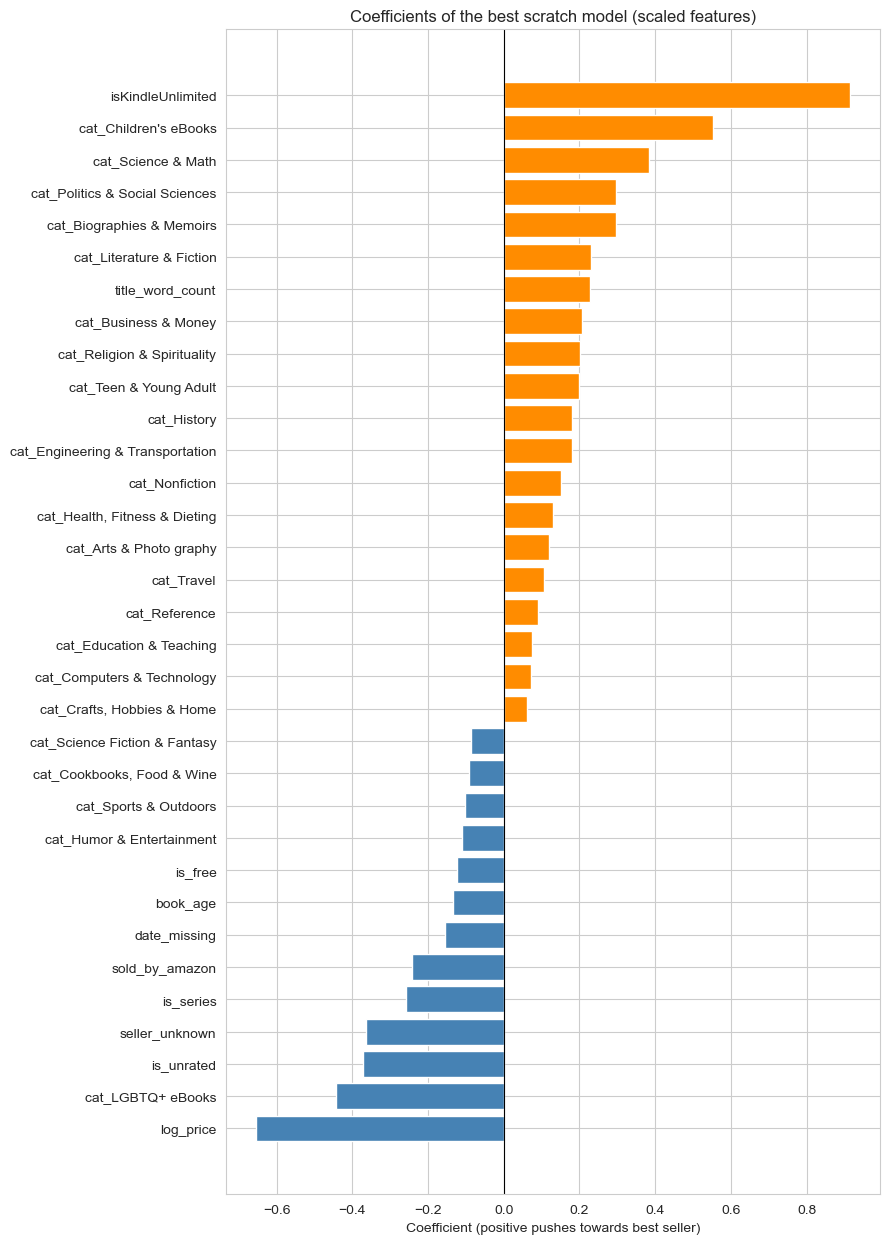

,coefficient,odds_ratio
isKindleUnlimited,0.9154,2.4977
cat_Children's eBooks,0.5520,1.7367
cat_Science & Math,0.3828,1.4663
cat_Politics & Social Sciences,0.2967,1.3454
cat_Biographies & Memoirs,0.2954,1.3436
cat_Literature & Fiction,0.2303,1.2589
title_word_count,0.2273,1.2552
cat_Business & Money,0.2056,1.2282
cat_Religion & Spirituality,0.2015,1.2233
cat_Teen & Young Adult,0.1994,1.2207


In [44]:
coef_table = pd.DataFrame({'coefficient': best_model.weights,
                           'odds_ratio': np.exp(best_model.weights)}, index=final_features)
coef_table = coef_table.sort_values('coefficient')

plt.figure(figsize=(9, 0.35 * len(coef_table) + 1))
colors = ['darkorange' if c > 0 else 'steelblue' for c in coef_table['coefficient']]
plt.barh(coef_table.index, coef_table['coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coefficients of the best scratch model (scaled features)')
plt.xlabel('Coefficient (positive pushes towards best seller)')
save_fig('16_coefficients.png')
plt.show()

coef_table.sort_values('coefficient', ascending=False).round(4)

Because every feature was scaled, the coefficients can be compared directly: each one shows how much one standard deviation of that feature changes the log odds of being a best seller, and the odds ratio shows the same thing as a multiplier. Orange bars push a book towards being a best seller and blue bars push it away. Kindle Unlimited is by far the strongest positive driver, with an odds ratio of 2.50, so being in Kindle Unlimited roughly increases the odds of being a best seller two and a half times for one standard deviation. Categories like Children's eBooks, Science & Math, Politics & Social Sciences and Biographies & Memoirs also push books up compared with the Mystery, Thriller & Suspense reference group, and longer titles help slightly (odds ratio 1.26). The strongest negative driver is price, with an odds ratio of 0.52, so more expensive books are much less likely to be best sellers. Being in LGBTQ+ eBooks, being unrated, having an unknown seller, being part of a series, being sold directly by Amazon and being older all lower the chance of being a best seller.

## 12. Conclusion and Limitations

In this project we built a logistic regression model from scratch in NumPy to predict whether a Kindle book will be a best seller. After cleaning the data, removing the Editors Pick and Goodreads Choice columns (which leak the answer because Amazon only shows one badge per book) and removing identifier columns, we engineered features such as log price, book age, seller groups, title features and one hot encoded categories. Backward elimination with statsmodels p values reduced 43 candidate features to 33.

The dataset is extremely imbalanced, with only 1.68 percent best sellers. Our first model reached 98.32 percent accuracy but found no best sellers at all, exactly like a model that always says "no". This proves accuracy is the wrong measure for this problem. By adding balanced class weights to the cost function and tuning the decision threshold to 0.84 on a validation set, the best model reached an F1 of 0.12, a recall of 0.22 and a precision of 0.08 on the test set, with a ROC AUC of 0.81. Changing the learning rate to 1.0 made training converge much faster, and L2 regularisation made little difference because the model was not overfitting. Our model gave exactly the same coefficients and predictions as scikit learn's LogisticRegression, which proves the implementation is correct.

For the book press, the most useful findings are that Kindle Unlimited books, cheaper books and books in categories like Children's eBooks, Science & Math and Biographies & Memoirs are much more likely to be best sellers, while expensive, unrated, older and series books are less likely.

**Limitations.** The model is only moderately useful in practice: even the best version wrongly flags about eleven books for every real best seller it finds, so it should be used to shortlist books rather than make final decisions. The review count was not collected for many categories, so it could not be used fairly. Some features, such as star ratings, reviews and price, are measured at the same time as the best seller badge, so they partly describe a book's success rather than predict it before release. The data is a single snapshot from 2023, so a book's status could change over time. Logistic regression can only draw a straight line boundary, so more flexible models such as decision trees or gradient boosting may capture patterns this model misses. Finally, important information like marketing budget, author popularity and the content of the book is not in the dataset at all.